In [8]:
import os
import glob
import time

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score
from catboost import CatBoostClassifier


In [2]:

VIEW = "structural"
TOP = 30                 
N_ROWS = None           
RANDOM_STATE = 42

D_STRUCT = "/kaggle/input/datasets/mdshagorahmed2011030/features-structural"
D_WORD = "/kaggle/input/datasets/mdshagorahmed2011030/features-source-code"
D_BYTE = "/kaggle/input/datasets/mdshagorahmed2011030/features-bytecode"

LABELS = ["access-control", "arithmetic", "other",
          "reentrancy", "safe", "unchecked-calls"]

In [3]:
def load_sparse(z, prefix):
    return sp.csr_matrix((z[prefix + "_data"], z[prefix + "_indices"],
                          z[prefix + "_indptr"]),
                         shape=tuple(z[prefix + "_shape"]))


In [5]:
y_train = pd.read_parquet("/kaggle/input/datasets/zerotoinfinitya/train-preprocessed/train_preprocessed.parquet",
                          columns=LABELS).values.astype(np.int8)
y_val = pd.read_parquet("/kaggle/input/datasets/zerotoinfinitya/validation-preprocessed/validation_preprocessed.parquet",
                        columns=LABELS).values.astype(np.int8)

In [6]:
if VIEW == "structural":
    tr = np.load(D_STRUCT + "/train_structural_features.npz")
    va = np.load(D_STRUCT + "/validation_structural_features.npz")
    X_train, X_val, names = tr["struct"], va["struct"], tr["names"]
elif VIEW == "hand":
    tr = np.load(D_BYTE + "/train_bytecode_features.npz")
    va = np.load(D_BYTE + "/validation_bytecode_features.npz")
    X_train, X_val, names = tr["bchand"], va["bchand"], tr["bchand_names"]
elif VIEW == "word":
    tr = np.load(D_WORD + "/train_source_code_features.npz")
    va = np.load(D_WORD + "/validation_source_code_features.npz")
    X_train, X_val = load_sparse(tr, "word"), load_sparse(va, "word")
    names = tr["vocabulary"]
elif VIEW == "opcode":
    tr = np.load(D_BYTE + "/train_bytecode_features.npz")
    va = np.load(D_BYTE + "/validation_bytecode_features.npz")
    X_train, X_val = load_sparse(tr, "bcops"), load_sparse(va, "bcops")
    names = tr["bcops_vocabulary"]

if N_ROWS:
    pick = np.random.RandomState(RANDOM_STATE).choice(
        X_train.shape[0], N_ROWS, replace=False)
    X_train, y_train = X_train[pick], y_train[pick]

print(VIEW, "train", X_train.shape, " val", X_val.shape)

structural train (79641, 52)  val (10861, 52)


In [9]:
model = CatBoostClassifier(
    loss_function="MultiLogloss",
    iterations=500,
    depth=6,
    learning_rate=0.1,
    early_stopping_rounds=50,
    random_seed=RANDOM_STATE,
    verbose=50,
)
model.fit(X_train, y_train, eval_set=(X_val, y_val))


0:	learn: 0.6047856	test: 0.6043361	best: 0.6043361 (0)	total: 207ms	remaining: 1m 43s
50:	learn: 0.2695299	test: 0.2698327	best: 0.2698327 (50)	total: 6.87s	remaining: 1m
100:	learn: 0.2396548	test: 0.2424636	best: 0.2424636 (100)	total: 13.5s	remaining: 53.4s
150:	learn: 0.2202601	test: 0.2257426	best: 0.2257426 (150)	total: 20.1s	remaining: 46.5s
200:	learn: 0.2067915	test: 0.2145732	best: 0.2145732 (200)	total: 26.7s	remaining: 39.7s
250:	learn: 0.1971117	test: 0.2069812	best: 0.2069812 (250)	total: 33.2s	remaining: 32.9s
300:	learn: 0.1885858	test: 0.2005164	best: 0.2005164 (300)	total: 39.8s	remaining: 26.3s
350:	learn: 0.1816552	test: 0.1953971	best: 0.1953971 (350)	total: 46.2s	remaining: 19.6s
400:	learn: 0.1752161	test: 0.1909049	best: 0.1909049 (400)	total: 52.8s	remaining: 13s
450:	learn: 0.1696740	test: 0.1871691	best: 0.1871691 (450)	total: 59.3s	remaining: 6.44s
499:	learn: 0.1647236	test: 0.1839001	best: 0.1839001 (499)	total: 1m 5s	remaining: 0us

bestTest = 0.18390005

CatBoostClassifier(depth=6, early_stopping_rounds=50, iterations=500, learning_rate=0.1, loss_function='MultiLogloss', random_seed=42, verbose=50)

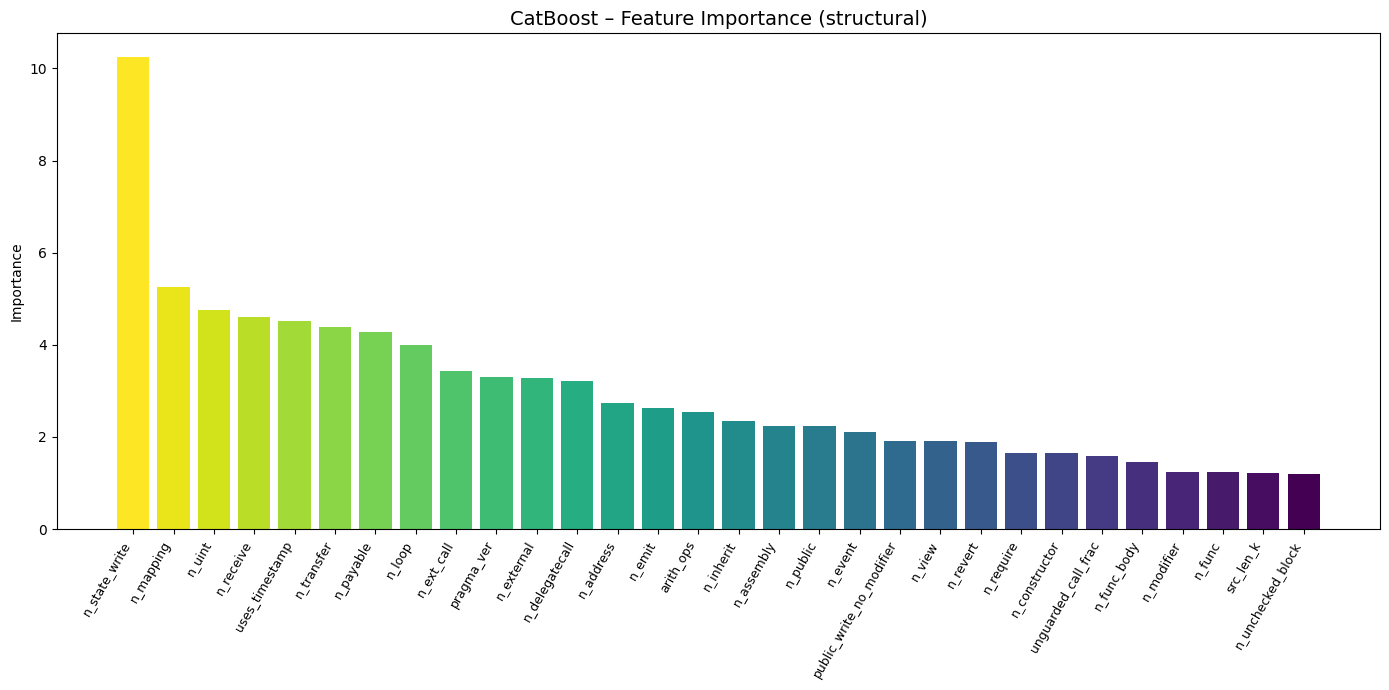

In [11]:
importance = model.get_feature_importance()  
order = np.argsort(-importance)[:TOP]

colors = plt.cm.viridis(np.linspace(1, 0, len(order)))   
plt.figure(figsize=(max(14, 0.32 * len(order)), 7))
plt.bar(range(len(order)), importance[order], color=colors)
plt.xticks(range(len(order)), [str(names[i]) for i in order],
           rotation=60, ha="right", fontsize=9)
plt.ylabel("Importance")
plt.title("CatBoost – Feature Importance (%s)" % VIEW, fontsize=14)
plt.tight_layout()
plt.savefig("/kaggle/working/catboost_importance_%s.png" % VIEW, dpi=200)
plt.show()